# SpaMosaic


支持 `data/` 下的两个数据集,在「0. 配置」里用 `DATASET` 切换:

| DATASET | 切片 1 | 切片 2 | 切片 3 | 参照的官方教程 |
|---|---|---|---|---|
| `Simulations` | RNA + ADT | 仅 RNA | 仅 ADT | `docs/.../mosaic/Simulations_with_batch_effects.ipynb` |
| `MB-H3K4me3` | RNA + H3K4me3 | 仅 RNA | 仅 H3K4me3 | `docs/.../mosaic/Mouse_postnatal_brain_rna+H3K4me3.ipynb` |

流程:配置 → 加载并检查数据结构 → 整理成 SpaMosaic 输入 → 预处理 → 训练 → 推理/聚类 → (可选)缺失模态填补。

In [1]:
import os
import sys
from os.path import join, abspath, exists

# 源码运行的关键:把仓库根目录加入 sys.path,使 import spamosaic 直接用源代码
REPO_ROOT = abspath('.')
assert exists(join(REPO_ROOT, 'spamosaic')), f'请在仓库根目录启动 notebook,当前目录: {REPO_ROOT}'
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

# CUDA >= 10.2 时需要(必须在 import torch 之前设置)
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'

import numpy as np
import pandas as pd
import scipy.sparse as sp
import scanpy as sc
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
import spamosaic.utils as utls
from spamosaic.train_utils import set_seeds
from spamosaic.framework import SpaMosaic
from spamosaic.preprocessing import RNA_preprocess, ADT_preprocess, Epigenome_preprocess

## 0. 配置

In [3]:
DATASET = 'MB-H3K4me3'              # 'Simulations' 或 'MB-H3K4me3'
SIM_SETTING = 'rna-0.1-12-adt-2.1'   # 仅 Simulations 用,data/Simulations 下共 5 种设置
SIM_REP = '1'                        # 仅 Simulations 用,重复 '1' / '2' / '3'
DEVICE = 'cuda:5'                       # 'cpu' 或 'cuda:0'
RUN_IMPUTE = True                   # 第 5 步填补很耗内存,MB-H3K4me3 尤其大
SEED = 1234

# 各数据集的参数取自对应的官方教程
PARAMS = {
    'Simulations': dict(input_key='X_pca_be', T=0.1, n_cluster=5, cluster_algo='kmeans', spot_size=[200, 200, 200]),
    'MB-H3K4me3':  dict(input_key='dimred_bc', T=0.01, n_cluster=7, cluster_algo='mclust', spot_size=[30, 30, 100]),
}
P = PARAMS[DATASET]

set_seeds(SEED)
OUT_DIR = join(REPO_ROOT, 'demo_out', DATASET)
os.makedirs(OUT_DIR, exist_ok=True)
sc.settings.figdir = OUT_DIR

## 1. 加载输入数据

每个「模态 × 切片」对应一个 AnnData。`LAYOUT` 描述马赛克结构:每个模态一个列表,列表下标就是切片序号,缺失的模态用 `None` 占位。

- `Simulations`:`ad_rna1` / `ad_adt1` 是切片 1(两种模态),`ad_rna2` 是切片 2(仅 RNA),`ad_adt2` 是切片 3(仅 ADT)。`ad_adt2` 的细胞名前缀是 `s3-`,所以它对应切片 3,下面 1.2 会核对这一点。
- `MB-H3K4me3`:`S1` 两种模态,`S2` 仅 RNA,`S3` 仅 H3K4me3。RNA 文件约 1.5 GB,并且 `.X` 以稠密矩阵存储,加载需要几 GB 内存。

In [4]:
if DATASET == 'Simulations':
    data_dir = join(REPO_ROOT, 'data/Simulations', SIM_SETTING, SIM_REP)
    files = ['ad_rna1', 'ad_adt1', 'ad_rna2', 'ad_adt2']
    LAYOUT = {
        'rna': ['ad_rna1', 'ad_rna2', None],
        'adt': ['ad_adt1', None,      'ad_adt2'],
    }
elif DATASET == 'MB-H3K4me3':
    data_dir = join(REPO_ROOT, 'data/MB-H3K4me3')
    files = ['S1/ad_rna', 'S1/ad_h3k4me3', 'S2/ad_rna', 'S3/ad_h3k4me3']
    LAYOUT = {
        'rna':     ['S1/ad_rna',     'S2/ad_rna', None],
        'H3K4me3': ['S1/ad_h3k4me3', None,        'S3/ad_h3k4me3'],
    }
else:
    raise ValueError(DATASET)

raw = {}
for f in files:
    raw[f] = sc.read_h5ad(join(data_dir, f + '.h5ad'))
    print(f'loaded {f}: {raw[f].shape}')

N_SEC = len(next(iter(LAYOUT.values())))
# 每个切片取第一个存在的模态作为该切片的代表(用于取坐标、gt 等)
SEC_REP = [next(LAYOUT[m][i] for m in LAYOUT if LAYOUT[m][i] is not None) for i in range(N_SEC)]

loaded S1/ad_rna: (9548, 21536)
loaded S1/ad_h3k4me3: (9548, 36768)
loaded S2/ad_rna: (9370, 21536)
loaded S3/ad_h3k4me3: (2499, 36768)


### 1.1 检查数据结构

SpaMosaic 对每个 AnnData 的要求:

- `.X`:原始 counts(细胞 × 基因/蛋白/peak)
- `.obsm['spatial']`:空间坐标
- `.obs['src']`:批次(切片)标签

先看原始文件里都有什么。

In [5]:
for name, ad in raw.items():
    print(f'===== {name} =====')
    print(ad, '\n')

===== S1/ad_rna =====
AnnData object with n_obs × n_vars = 9548 × 21536
    obs: 'src'
    obsm: 'spatial' 

===== S1/ad_h3k4me3 =====
AnnData object with n_obs × n_vars = 9548 × 36768
    obs: 'src'
    obsm: 'spatial' 

===== S2/ad_rna =====
AnnData object with n_obs × n_vars = 9370 × 21536
    obs: 'src'
    obsm: 'spatial' 

===== S3/ad_h3k4me3 =====
AnnData object with n_obs × n_vars = 2499 × 36768
    obs: 'src'
    obsm: 'spatial' 



In [6]:
def x_summary(X, n_rows=2000):
    # 只取前 n_rows 行估计取值,避免对整块大矩阵做计算
    sub = X[:n_rows]
    vals = sub.data if sp.issparse(sub) else np.asarray(sub)
    return dict(
        X_type=f'sparse {sub.format}' if sp.issparse(sub) else 'dense',
        dtype=str(X.dtype),
        min=float(sub.min()),
        max=float(sub.max()),
        is_integer=bool(np.allclose(vals, np.round(vals))),
    )

rows = []
for name, ad in raw.items():
    rows.append(dict(
        name=name, n_obs=ad.n_obs, n_vars=ad.n_vars, **x_summary(ad.X),
        layers=[k for k in ad.layers.keys() if k is not None],  # 新版 anndata 会把 .X 列为 layers[None]
        obs_cols=list(ad.obs.columns),
        obsm=list(ad.obsm.keys()),
        has_spatial='spatial' in ad.obsm,
        has_src='src' in ad.obs,
        first_obs=ad.obs_names[0],
        first_var=ad.var_names[0],
    ))
summary = pd.DataFrame(rows).set_index('name')
display(summary)

,n_obs,n_vars,X_type,dtype,min,max,is_integer,layers,obs_cols,obsm,has_spatial,has_src,first_obs,first_var
name,,,,,,,,,,,,,,
S1/ad_rna,9548,21536,dense,int64,0.0,699.0,True,[],[src],[spatial],True,True,mult-CTAAGGTCAACGTGAT,Gm26752
S1/ad_h3k4me3,9548,36768,sparse csr,int64,0.0,13.0,True,[],[src],[spatial],True,True,mult-CTAAGGTCAACGTGAT,chr1-3433875-3434074
S2/ad_rna,9370,21536,dense,int64,0.0,936.0,True,[],[src],[spatial],True,True,rna-CTAAGGTCACAAGCTA,Gm26752
S3/ad_h3k4me3,2499,36768,sparse csr,int64,0.0,12.0,True,[],[src],[spatial],True,True,atac-AACGTGATAAACATCG,chr1-3433875-3434074


In [7]:
# 每个对象的 obs / var / spatial / layers 细节
for name, ad in raw.items():
    print(f'\n===== {name} =====')
    display(ad.obs.head())
    for c in ad.obs.columns:
        if ad.obs[c].nunique() <= 20:
            print(f'obs["{c}"] 取值分布:', ad.obs[c].value_counts().to_dict())
    display(ad.var.head())
    xy = np.asarray(ad.obsm['spatial'])
    print('spatial:', xy.shape, xy.dtype, '| min', xy.min(0), '| max', xy.max(0))
    for k in ad.layers.keys():
        if k is None:
            continue
        print(f'layers["{k}"]:', x_summary(ad.layers[k]))


===== S1/ad_rna =====


,src
mult-CTAAGGTCAACGTGAT,mult
mult-CTAAGGTCACAAGCTA,mult
mult-CTAAGGTCTTGCTGGA,mult
mult-CTAAGGTCCTGTAGCC,mult
mult-CTAAGGTCAGTACAAG,mult


obs["src"] 取值分布: {'mult': 9548}


""
Gm26752
Ppp1r14c
Iyd
Plekhg1
Mthfd1l


spatial: (9548, 2) int64 | min [-99 -98] | max [ 0 -1]

===== S1/ad_h3k4me3 =====


...

spatial: (9370, 2) int64 | min [-99 -98] | max [ 0 -1]

===== S3/ad_h3k4me3 =====


,src
atac-AACGTGATAAACATCG,atac
atac-AACGTGATATGCCTAA,atac
atac-AACGTGATAGTGGTCA,atac
atac-AACGTGATACCACTGT,atac
atac-AACGTGATACATTGGC,atac


obs["src"] 取值分布: {'atac': 2499}


""
chr1-3433875-3434074
chr1-3670113-3672402
chr1-4471407-4471612
chr1-4491703-4493730
chr1-4496203-4496619


spatial: (2499, 2) int64 | min [  0 -49] | max [49  0]


### 1.2 一致性检查

- 同一切片的不同模态:细胞名(含顺序)和空间坐标应完全一致。
- 同一模态的不同切片:特征名应一致,否则 `sc.concat` 会取交集。
- 所有切片的细胞名不能重复,SpaMosaic 内部按细胞名区分切片。

In [8]:
for i in range(N_SEC):
    names = [LAYOUT[m][i] for m in LAYOUT if LAYOUT[m][i] is not None]
    print(f'切片 {i+1}: {names}')
    if len(names) > 1:
        a, b = raw[names[0]], raw[names[1]]
        print('  obs_names 完全一致(含顺序):', a.obs_names.equals(b.obs_names))
        print('  共同细胞数:', len(a.obs_names.intersection(b.obs_names)), '/', a.n_obs, b.n_obs)
        if a.n_obs == b.n_obs:
            print('  spatial 一致:', np.allclose(np.asarray(a.obsm['spatial']), np.asarray(b.obsm['spatial'])))
        if 'gt' in a.obs and 'gt' in b.obs and a.obs_names.equals(b.obs_names):
            print('  gt 一致比例:', float((a.obs['gt'].astype(str) == b.obs['gt'].astype(str)).mean()))

print()
for m, names in LAYOUT.items():
    ads = [raw[n] for n in names if n is not None]
    same = all(ads[0].var_names.equals(x.var_names) for x in ads[1:])
    print(f'{m}: 各切片特征名一致 = {same}, n_vars = {[x.n_vars for x in ads]}')

all_obs = pd.Index(np.concatenate([raw[n].obs_names.to_numpy() for n in SEC_REP]))
print('\n跨切片细胞名是否唯一:', all_obs.is_unique)
print('各切片细胞名前缀:', [raw[n].obs_names[0].split('-')[0] for n in SEC_REP])

切片 1: ['S1/ad_rna', 'S1/ad_h3k4me3']
  obs_names 完全一致(含顺序): True
  共同细胞数: 9548 / 9548 9548
  spatial 一致: True
切片 2: ['S2/ad_rna']
切片 3: ['S3/ad_h3k4me3']

rna: 各切片特征名一致 = True, n_vars = [21536, 21536]
H3K4me3: 各切片特征名一致 = True, n_vars = [36768, 36768]

跨切片细胞名是否唯一: True
各切片细胞名前缀: ['mult', 'rna', 'atac']


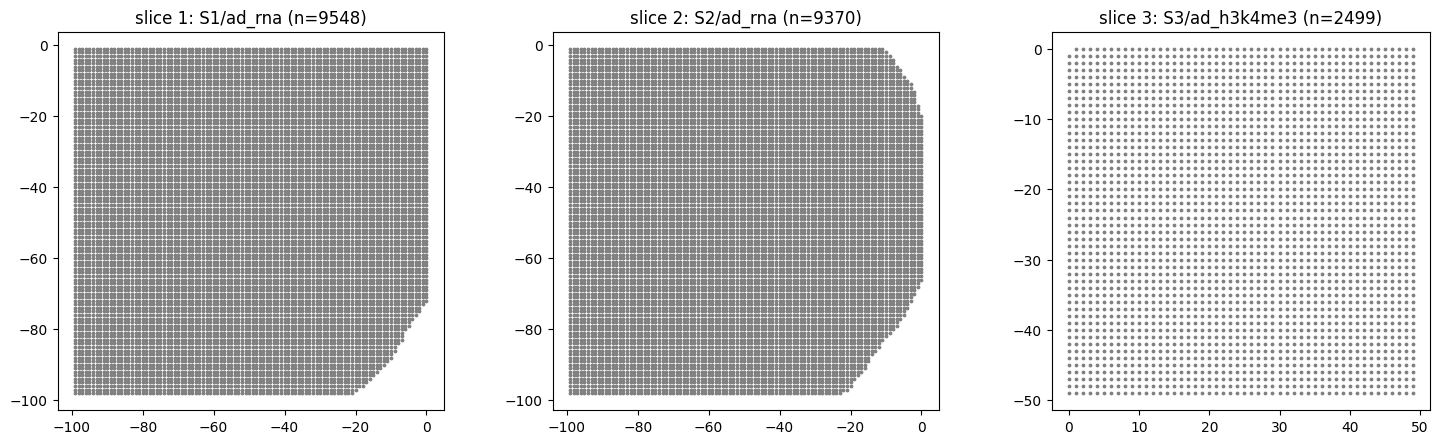

In [9]:
# 空间分布:有 gt 时按 gt 上色
fig, axes = plt.subplots(1, N_SEC, figsize=(5 * N_SEC, 4.5))
for i, ax in enumerate(np.atleast_1d(axes)):
    ad = raw[SEC_REP[i]]
    xy = np.asarray(ad.obsm['spatial'])
    color = dict(c=ad.obs['gt'].astype('category').cat.codes, cmap='tab10') if 'gt' in ad.obs else dict(c='grey')
    ax.scatter(xy[:, 0], xy[:, 1], s=3, **color)
    ax.set_title(f'slice {i+1}: {SEC_REP[i]} (n={ad.n_obs})')
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

### 1.3 整理成 SpaMosaic 需要的格式

- `Simulations`:原始文件没有 `src` 列,`.X` 是 scale 后的值,原始 counts 在 `layers['counts']`。这里补上 `src`,并把 `.X` 换回 counts(与官方教程一致)。
- `MB-H3K4me3`:已有 `src`(`mult` / `rna` / `atac`),`.X` 就是 counts。RNA 的 `.X` 是稠密 int64,转成稀疏 float32 以节省内存,数值不变。

In [10]:
if DATASET == 'Simulations':
    src_labels = ['mult', 'rna', 'adt']  # 切片 1 / 2 / 3
    for m, names in LAYOUT.items():
        for i, n in enumerate(names):
            if n is None:
                continue
            raw[n].obs['src'] = src_labels[i]
            raw[n].X = raw[n].layers['counts'].copy()

if DATASET == 'MB-H3K4me3':
    for ad in raw.values():
        if not sp.issparse(ad.X):
            ad.X = sp.csr_matrix(ad.X, dtype=np.float32)

input_dict = {m: [raw[n] if n is not None else None for n in names] for m, names in LAYOUT.items()}

# 进入预处理前的最终检查
for m, ads in input_dict.items():
    for i, ad in enumerate(ads):
        if ad is None:
            continue
        assert 'spatial' in ad.obsm, f'{m} 切片{i+1} 缺少 obsm["spatial"]'
        assert 'src' in ad.obs, f'{m} 切片{i+1} 缺少 obs["src"]'
        assert x_summary(ad.X)['is_integer'], f'{m} 切片{i+1} 的 X 看起来不是原始 counts'

display(pd.DataFrame(
    {m: [f'{ad.n_obs} x {ad.n_vars}, src={ad.obs["src"].iloc[0]}' if ad is not None else '-' for ad in ads]
     for m, ads in input_dict.items()},
    index=[f'slice{i+1}' for i in range(N_SEC)],
))

,rna,H3K4me3
slice1,"9548 x 21536, src=mult","9548 x 36768, src=mult"
slice2,"9370 x 21536, src=rna",-
slice3,-,"2499 x 36768, src=atac"


## 2. 预处理

各模态做归一化、特征选择、降维,并用 Harmony 做批次校正,结果写入每个 AnnData 的 `obsm[input_key]`。参数与对应的官方教程一致。

In [12]:
input_key = P['input_key']

if DATASET == 'Simulations':
    RNA_preprocess(input_dict['rna'], batch_corr=True, favor='scanpy', n_hvg=None,
                   lognorm=False, scale=True, batch_key='src', key=input_key)
    ADT_preprocess(input_dict['adt'], batch_corr=True, favor='scanpy',
                   lognorm=False, scale=True, batch_key='src', key=input_key)
else:
    RNA_preprocess(input_dict['rna'], batch_corr=True, n_hvg=5000,
                   batch_key='src', key=input_key)
    Epigenome_preprocess(input_dict['H3K4me3'], batch_corr=True, n_peak=50000,
                         batch_key='src', key=input_key)

for m, ads in input_dict.items():
    print(m, [ad.obsm[input_key].shape if ad is not None else None for ad in ads])

Use GPU mode.
	Initialization is completed.
	Completed 1 / 10 iteration(s).
	Completed 2 / 10 iteration(s).
	Completed 3 / 10 iteration(s).
Reach convergence after 3 iteration(s).
Use GPU mode.
	Initialization is completed.
	Completed 1 / 10 iteration(s).
	Completed 2 / 10 iteration(s).
Reach convergence after 2 iteration(s).
rna [(9548, 50), (9370, 50), None]
H3K4me3 [(9548, 50), None, (2499, 50)]


## 3. 初始化模型 + 训练

初始化时内部会构建空间图和跨切片 MNN 图。

In [13]:
model = SpaMosaic(
    modBatch_dict=input_dict, input_key=input_key,
    batch_key='src',
    intra_knns=10, inter_knn_base=10,
    w_g=0.8,
    seed=SEED,
    device=DEVICE,
)
model.train(net='wlgcn', lr=0.01, T=P['T'], n_epochs=100)

batch0: ['rna', 'H3K4me3']
batch1: ['rna']
batch2: ['H3K4me3']
------Calculating spatial graph...
The graph contains 95480 edges, 9548 cells.
10.0000 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 93700 edges, 9370 cells.
10.0000 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 95480 edges, 9548 cells.
10.0000 neighbors per cell on average.
------Calculating spatial graph...
The graph contains 24990 edges, 2499 cells.
10.0000 neighbors per cell on average.
Searching MNN within rna
Finding MNN between (mult, rna) using KNN (10, 10)
Number of mnn pairs for rna:12001
Searching MNN within H3K4me3
Finding MNN between (mult, atac) using KNN (10, 10)
Number of mnn pairs for H3K4me3:8220


100%|██████████| 100/100 [00:03<00:00, 30.84it/s]


## 4. 推理嵌入 + 聚类

`infer_emb` 返回每个切片一个新的 AnnData,融合后的嵌入存于 `obsm['merged_emb']`。图保存在 `demo_out/<DATASET>/`。

/data/home/jiboya/.conda/envs/spamosaic-env/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


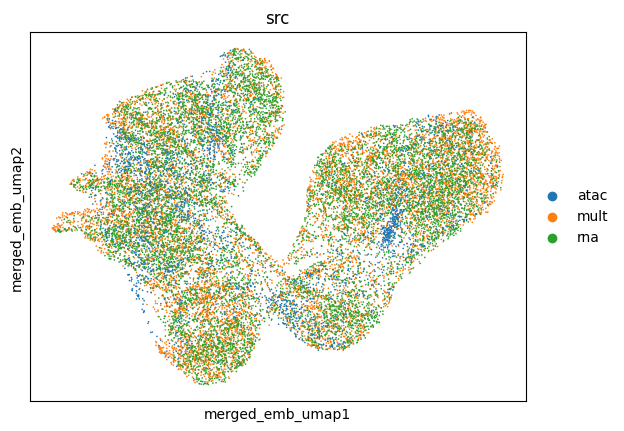

In [14]:
ad_embs = model.infer_emb(input_dict, emb_key='emb', final_latent_key='merged_emb')
ad_mosaic = sc.concat(ad_embs)
ad_mosaic = utls.get_umap(ad_mosaic, use_reps=['merged_emb'])
utls.plot_basis(ad_mosaic, basis='merged_emb_umap', color=['src'], save='_umap_src.png')

R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.0.0
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


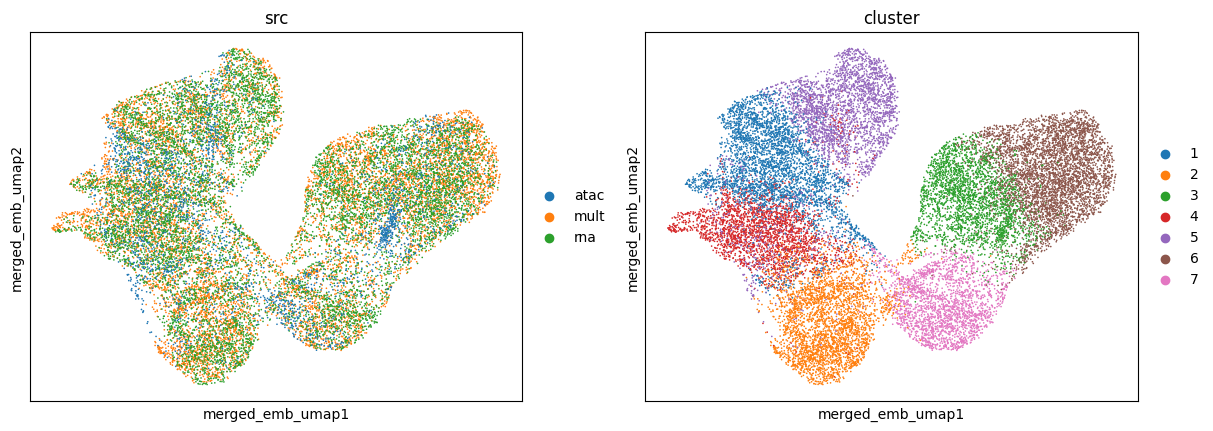

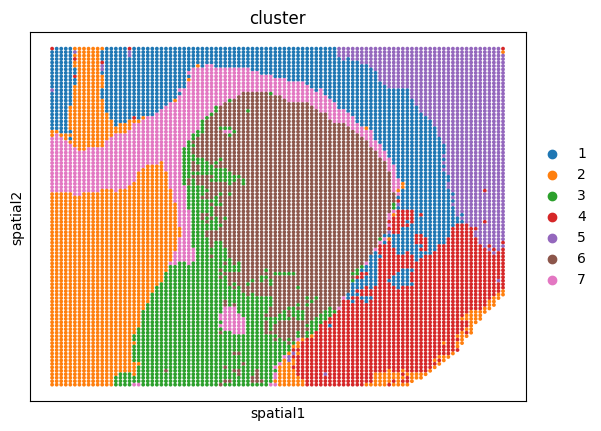

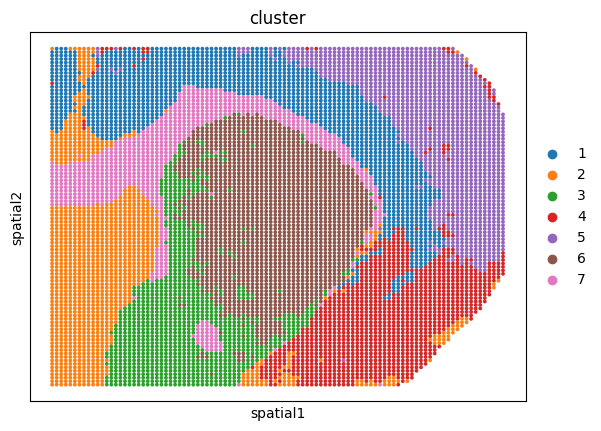

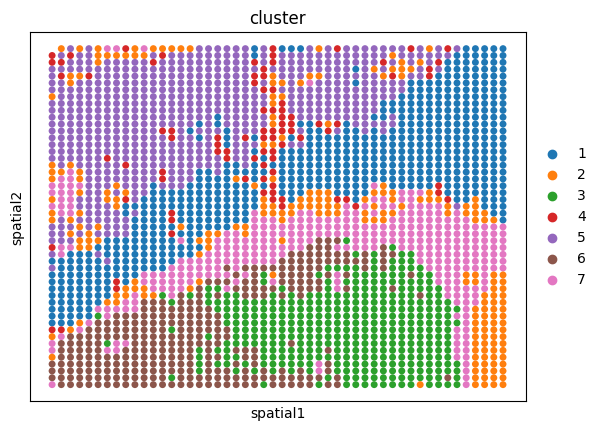

In [15]:
# mclust 需要 R + rpy2,失败时会自动退回 kmeans
ad_mosaic = utls.clustering(ad_mosaic, n_cluster=P['n_cluster'], used_obsm='merged_emb',
                            algo=P['cluster_algo'], key='cluster')
utls.split_adata_ob(ad_embs, ad_mosaic, 'obs', 'cluster')

utls.plot_basis(ad_mosaic, basis='merged_emb_umap', color=['src', 'cluster'], save='_umap_cluster.png')
for i, ad in enumerate(ad_embs):
    utls.plot_basis(ad, 'spatial', 'cluster', s=P['spot_size'][i], save=f'_spatial_slice{i+1}.png')

In [16]:
# 有 ground truth 时(Simulations)计算各切片的 ARI
from sklearn.metrics import adjusted_rand_score

for i, ad in enumerate(ad_embs):
    ref = raw[SEC_REP[i]]
    if 'gt' not in ref.obs:
        continue
    gt = ref.obs.loc[ad.obs_names, 'gt'].astype(str)
    print(f'slice{i+1} ARI = {adjusted_rand_score(gt, ad.obs["cluster"]):.4f}')

## 5. (可选)缺失模态填补

`RUN_IMPUTE = True` 时运行。`layers['counts']` 指定待填补的 layer。

In [17]:
if RUN_IMPUTE:
    for ads in input_dict.values():
        for ad in ads:
            if ad is not None:
                ad.layers['counts'] = ad.X.copy()
    imputed_featureDict = model.impute(input_dict, emb_key='emb', layer_key='counts', imp_knn=10)
    print('填补结果 keys:', list(imputed_featureDict.keys()))
    for k, v in imputed_featureDict.items():
        print(k, [x.shape if x is not None else None for x in v])

impute H3K4me3-counts for batch-2
impute rna-counts for batch-3
填补结果 keys: ['rna', 'H3K4me3']
rna [None, None, (2499, 21536)]
H3K4me3 [None, (9370, 36768), None]
